# Estudio del dataset Smartphone Photography Attribute and Quality  - Fase 3

Reconstrucción reproducible desde 11.125 JPEG y tres Excel originales. Conserva los
68 descriptores, 14 predictores, partición SHA, modelos y análisis aprobados.

In [1]:
import hashlib, io, json, platform, random, time, warnings
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo
import cv2, joblib, numpy as np, pandas as pd, scipy, seaborn as sns, sklearn, torch
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image, ImageCms, ImageOps
from joblib import parallel_backend
from scipy.stats import spearmanr
from skimage.feature import local_binary_pattern
from sklearn import base, cluster, decomposition, ensemble, impute, inspection
from sklearn import linear_model, metrics as skm, model_selection, neighbors, pipeline, preprocessing
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

ROOT, SEED, WORKERS = Path(r"RUTA_DEL_PROYECTO"), 20261115, 16
SPAQ, PACKAGE = ROOT / "spaq/SPAQ", ROOT / "SPAQ_FASE3_COMPACTO"
ANNOTATIONS, IMAGES = SPAQ / "Annotations", SPAQ / "TestImage"
RESULTS, FIGURES = PACKAGE / "resultados_sg3", PACKAGE / "resultados_sg3/figuras"
MODELS = PACKAGE / "resultados_sg3/modelos"
for folder in (PACKAGE, RESULTS, FIGURES, MODELS): folder.mkdir(parents=True, exist_ok=True)
FILES = {name: ANNOTATIONS / filename for name, filename in {"scores": "MOS and Image attribute scores.xlsx",
    "scenes": "Scene category labels.xlsx", "exif": "EXIF_tags.xlsx"}.items()}
SCENES = "Animal|Cityscape|Human|Indoor scene|Landscape|Night scene|Plant|Still-life|Others".split("|")
PREDICTORS = """s512_luma_mean s512_luma_std heterogeneity_ratio luma_p95_minus_p05
s512_gradient_mean s512_laplacian_var s512_fft_high_fraction s512_entropy hsv_s_mean
lab_chroma_mean color_entropy neighbor_absdiff lbp_entropy tile_entropy_std""".split()
FAMILY_GROUPS = {"tonal": "s512_luma_mean s512_luma_std luma_p95_minus_p05",
    "regional": "heterogeneity_ratio tile_entropy_std",
    "spatial": "s512_gradient_mean s512_laplacian_var neighbor_absdiff lbp_entropy",
    "multiscale": "s512_fft_high_fraction s512_entropy", "chromatic": "hsv_s_mean lab_chroma_mean color_entropy"}
FAMILIES = {name: family for family, names in FAMILY_GROUPS.items() for name in names.split()}
BASE = "luma_mean luma_std gradient_mean laplacian_var fft_high_fraction tile_mean_std entropy".split()
EXTRA = """analysis_width analysis_height luma_median luma_min luma_max luma_range luma_skew gradient_p95
tile_gradient_cv tile_dark_fraction tile_bright_fraction tile_entropy_mean tile_entropy_std hsv_s_mean hsv_s_std
hsv_v_mean rgb_r_mean rgb_g_mean rgb_b_mean rgb_r_minus_g rgb_b_minus_g lab_l_mean lab_a_mean lab_b_mean
lab_chroma_mean lab_chroma_std tile_chroma_std color_entropy tile_color_entropy_std lbp_entropy neighbor_absdiff
fft_centroid""".split()
DESCRIPTORS = ([f"s{s}_{name}" for s in (512, 256, 128) for name in BASE] + EXTRA
    + [f"luma_p{p:02}" for p in (1, 5, 25, 75, 95, 99)] + [f"near_black_{p:02}" for p in (1, 5, 10)]
    + [name for p in (245, 250, 254) for name in (f"near_white_{p}", f"channel_clip_{p}")])
for seed in (random.seed, np.random.seed, torch.manual_seed): seed(SEED)
warnings.filterwarnings("ignore", category=UserWarning); cv2.setNumThreads(1); sns.set_theme(style="whitegrid")
assert len(DESCRIPTORS) == 68 and len(PREDICTORS) == 14

def save(fig, name, title, top=.94):
    fig.suptitle(title, y=.99); fig.tight_layout(rect=(0, 0, 1, top))
    for suffix, kwargs in (("png", {"dpi": 240}), ("svg", {})):
        fig.savefig(FIGURES / f"{name}.{suffix}", bbox_inches="tight", **kwargs)
    plt.show()

def annotations(path, keep=None):
    frame = pd.read_excel(path); frame["image_id"] = frame["Image name"].map(lambda x: Path(str(x)).stem.zfill(5))
    return frame if keep is None else frame.loc[frame.image_id.isin(keep)].copy()

versions = {"date": datetime.now(ZoneInfo("America/Bogota")).isoformat(), "python": platform.python_version(),
    **{k: v.__version__ for k, v in {"numpy": np, "pandas": pd, "scipy": scipy, "opencv": cv2,
        "scikit_learn": sklearn, "torch": torch}.items()}}
(RESULTS / "versiones.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")

208

## Descriptores de imagen

In [2]:
def entropy(values, bins=256):
    return float(scipy.stats.entropy(np.histogram(values, bins=bins, range=(0, 1))[0], base=2))

def color_entropy(rgb):
    q = np.minimum((rgb * 8).astype(np.int32), 7)
    return float(scipy.stats.entropy(np.bincount((q[:, :, 0] * 64 + q[:, :, 1] * 8 + q[:, :, 2]).ravel(),
        minlength=512), base=2))

def tiles(values):
    return [tile for row in np.array_split(values, 4, axis=0) for tile in np.array_split(row, 4, axis=1)]

def spectrum(luma):
    height, width = luma.shape
    power = np.abs(np.fft.rfft2((luma - luma.mean()) * np.outer(np.hanning(height), np.hanning(width)),
        norm="ortho")) ** 2
    weights = np.full(power.shape[1], 2.); weights[0] = 1
    if width % 2 == 0: weights[-1] = 1
    power *= weights[None, :]; power[0, 0] = 0
    radius = np.hypot(np.fft.fftfreq(height)[:, None], np.fft.rfftfreq(width)[None, :]); total = power.sum()
    if total <= 1e-20: return None, None
    return float(power[radius >= .25].sum() / total), float((power * radius).sum() / total)

def extract_features(image):
    result = {}
    for scale in (512, 256, 128):
        width, height = image.size; factor = min(1, scale / max(width, height))
        size = max(1, round(width * factor)), max(1, round(height * factor))
        rgb = np.asarray(image.resize(size, Image.Resampling.LANCZOS), dtype=np.float32) / 255
        luma = rgb @ np.array([.2126, .7152, .0722], dtype=np.float32)
        gx, gy = (cv2.Sobel(luma, cv2.CV_32F, dx, dy, ksize=3) / 8 for dx, dy in ((1, 0), (0, 1)))
        gradient, luma_tiles = np.hypot(gx, gy), tiles(luma)
        tile_means, (high, centroid) = np.array([x.mean() for x in luma_tiles]), spectrum(luma)
        prefix = f"s{scale}_"
        result.update({prefix + "luma_mean": float(luma.mean()), prefix + "luma_std": float(luma.std()),
            prefix + "gradient_mean": float(gradient.mean()), prefix + "laplacian_var": float(
                cv2.Laplacian(luma, cv2.CV_32F, ksize=1).var()), prefix + "fft_high_fraction": high,
            prefix + "tile_mean_std": float(tile_means.std()), prefix + "entropy": entropy(luma)})
        if scale != 512: continue
        std = float(luma.std()); centered = (luma - luma.mean()) ** 3
        result.update({"analysis_width": luma.shape[1], "analysis_height": luma.shape[0],
            "luma_median": float(np.median(luma)), "luma_min": float(luma.min()), "luma_max": float(luma.max()),
            "luma_range": float(np.ptp(luma)), "luma_skew": float(centered.mean() / std**3) if std > 1e-8 else None})
        for p, value in zip((1, 5, 25, 75, 95, 99), np.percentile(luma, (1, 5, 25, 75, 95, 99))):
            result[f"luma_p{p:02}"] = float(value)
        for p in (1, 5, 10): result[f"near_black_{p:02}"] = float(np.mean(luma <= p / 255))
        for p in (245, 250, 254):
            result[f"near_white_{p}"] = float(np.mean(luma >= p / 255))
            result[f"channel_clip_{p}"] = float(np.mean(rgb.max(axis=2) >= p / 255))
        gradient_means = np.array([x.mean() for x in tiles(gradient)])
        tile_entropies = np.array([entropy(x) for x in luma_tiles])
        hsv, lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV), cv2.cvtColor(rgb, cv2.COLOR_RGB2Lab)
        chroma, rgb_mean = np.hypot(lab[:, :, 1], lab[:, :, 2]), rgb.mean(axis=(0, 1))
        differences = (np.abs(np.diff(luma, axis=0)).mean() + np.abs(np.diff(luma, axis=1)).mean()) / 2
        result.update({"gradient_p95": float(np.percentile(gradient, 95)),
            "tile_gradient_cv": float(gradient_means.std() / gradient_means.mean()) if gradient_means.mean() > 1e-8 else None,
            "tile_dark_fraction": float(np.mean(tile_means < .1)), "tile_bright_fraction": float(np.mean(tile_means > .9)),
            "tile_entropy_mean": float(tile_entropies.mean()), "tile_entropy_std": float(tile_entropies.std()),
            "fft_centroid": centroid, "hsv_s_mean": float(hsv[:, :, 1].mean()), "hsv_s_std": float(hsv[:, :, 1].std()),
            "hsv_v_mean": float(hsv[:, :, 2].mean()), "rgb_r_mean": float(rgb_mean[0]), "rgb_g_mean": float(rgb_mean[1]),
            "rgb_b_mean": float(rgb_mean[2]), "rgb_r_minus_g": float(rgb_mean[0] - rgb_mean[1]),
            "rgb_b_minus_g": float(rgb_mean[2] - rgb_mean[1]), "lab_l_mean": float(lab[:, :, 0].mean()),
            "lab_a_mean": float(lab[:, :, 1].mean()), "lab_b_mean": float(lab[:, :, 2].mean()),
            "lab_chroma_mean": float(chroma.mean()), "lab_chroma_std": float(chroma.std()),
            "tile_chroma_std": float(np.std([x.mean() for x in tiles(chroma)])), "color_entropy": color_entropy(rgb),
            "tile_color_entropy_std": float(np.std([color_entropy(x) for x in tiles(rgb)])),
            "neighbor_absdiff": float(differences)})
        lbp = local_binary_pattern(np.round(luma * 255).astype(np.uint8), 8, 1, "uniform")[1:-1, 1:-1]
        counts = np.bincount(lbp.astype(int).ravel(), minlength=10); probabilities = counts[counts > 0] / counts.sum()
        result["lbp_entropy"] = float(-(probabilities * np.log2(probabilities)).sum())
    assert set(result) == set(DESCRIPTORS)
    return result

SRGB = ImageCms.createProfile("sRGB")
def process_image(image_id):
    content = (IMAGES / f"{image_id}.jpg").read_bytes()
    with Image.open(io.BytesIO(content)) as raw:
        raw.load(); image = ImageOps.exif_transpose(raw); profile = raw.info.get("icc_profile")
        try:
            if profile: image = ImageCms.profileToProfile(image, ImageCms.ImageCmsProfile(io.BytesIO(profile)),
                SRGB, outputMode="RGB")
        except Exception: pass
        values = extract_features(image.convert("RGB"))
    return {"image_id": image_id, "sha256": hashlib.sha256(content).hexdigest(), **values}

## Datos, SHA y partición

In [3]:
score_ids = annotations(FILES["scores"])[["Image name", "image_id"]]
assert len(score_ids) == len(pd.read_excel(FILES["exif"])) == 11125
assert list(pd.read_excel(FILES["scenes"], nrows=0)) == ["Image name", *SCENES]
image_ids = sorted(score_ids.image_id); pilot = pd.DataFrame(map(process_image, image_ids[:5]))
assert pilot.shape == (5, 70) and pilot[DESCRIPTORS].notna().all().all(); display(pilot.iloc[:, :4])
start = time.time()
with ThreadPoolExecutor(max_workers=WORKERS) as executor: images = pd.DataFrame(executor.map(process_image, image_ids))
extraction_minutes = (time.time() - start) / 60
assert len(images) == 11125 and images.sha256.nunique() == 10803
def split_sha(sha):
    value = int(hashlib.sha256(f"{SEED}|{sha}".encode()).hexdigest()[:16], 16) / 2**64
    return "train" if value < .75 else "validation" if value < .875 else "test"
metadata = images.assign(heterogeneity_ratio=images.s512_tile_mean_std / images.s512_luma_std,
    luma_p95_minus_p05=images.luma_p95 - images.luma_p05, split=images.sha256.map(split_sha))
metadata.loc[metadata.s512_luma_std <= 1e-8, "heterogeneity_ratio"] = np.nan
metadata["sha_weight"] = 1 / metadata.sha256.map(metadata.groupby("sha256").size())
development_ids = set(metadata.loc[metadata.split != "test", "image_id"])
development = annotations(FILES["scores"], development_ids).merge(annotations(FILES["scenes"], development_ids),
    on=["image_id", "Image name"], validate="one_to_one").merge(metadata.query("split != 'test'"), on="image_id")
TARGETS = [f"target_{scene}" for scene in SCENES]
development[TARGETS] = (development[SCENES] > 0).astype("int8").set_axis(TARGETS, axis=1)
train, validation = [development.query("split == @name").copy() for name in ("train", "validation")]
test_sealed = metadata.query("split == 'test'").copy(); split_counts = metadata.split.value_counts()
assert split_counts.to_dict() == {"train": 8364, "test": 1396, "validation": 1365}
assert metadata.groupby("sha256").split.nunique().max() == 1 and "MOS" not in test_sealed
X_train, y_train, Y_train = train[PREDICTORS], train.MOS, train[TARGETS].to_numpy()
X_validation, y_validation, Y_validation = validation[PREDICTORS], validation.MOS, validation[TARGETS].to_numpy()
groups_train, group_cv = train.sha256, model_selection.GroupKFold(3)

,image_id,sha256,s512_luma_mean,s512_luma_std
0,00001,0a1dcb4b6759130f41a089eaafa53176463f02141f685d...,0.460585,0.251393
1,00002,a01f7dc1429764a0c2c44f2024473c1dee74ab83f8241a...,0.318680,0.217884
2,00003,04951d9704ec68917896f79ca7fc8667833fa976f30230...,0.426044,0.292064
3,00004,e973f536a8955cc62d9b424e926ff92b068fc4aebec831...,0.421824,0.244125
4,00005,e2406ffe8d91cba5495229b28a65adb34e7f895d044742...,0.359360,0.250307


## Regresión y clasificación multietiqueta

In [4]:
def reg_metrics(y, prediction):
    return {"MAE": skm.mean_absolute_error(y, prediction), "RMSE": skm.mean_squared_error(y, prediction) ** .5,
        "R2": skm.r2_score(y, prediction)}
def reg_table(frame, prediction):
    return frame[["image_id", "sha256", "split", "MOS", *SCENES]].copy().assign(MOS_predicted=prediction,
        residual=lambda x: x.MOS - x.MOS_predicted, absolute_error=lambda x: x.residual.abs())
def scores(model, values): return np.column_stack([x[:, 1] for x in model.predict_proba(values)])
def class_metrics(y, prediction, score):
    precision, recall, f1, _ = skm.precision_recall_fscore_support(y, prediction, average="micro", zero_division=0)
    return {"F1_micro": f1, "F1_macro": skm.f1_score(y, prediction, average="macro", zero_division=0),
        "Precision_micro": precision, "Recall_micro": recall, "Hamming_loss": skm.hamming_loss(y, prediction),
        "Subset_accuracy": skm.accuracy_score(y, prediction), "AUC_macro": skm.roc_auc_score(y, score, average="macro")}
def class_table(frame, y, prediction, score):
    blocks = [frame[["image_id", "sha256", "split"]].reset_index(drop=True)]
    blocks += [pd.DataFrame(x, columns=SCENES).add_prefix(prefix) for x, prefix in
        ((y, "observed_"), (prediction, "predicted_"), (score, "score_"))]
    return pd.concat(blocks, axis=1)
def search(estimator, parameters, scoring, y):
    grid = model_selection.GridSearchCV(estimator, parameters, scoring=scoring, cv=group_cv, n_jobs=-1)
    with parallel_backend("threading", n_jobs=WORKERS): grid.fit(X_train, y, groups=groups_train)
    return grid

ridge = search(pipeline.make_pipeline(impute.SimpleImputer(strategy="median"), preprocessing.RobustScaler(),
    linear_model.Ridge()), {"ridge__alpha": [.1, 1., 10., 100.]}, "neg_root_mean_squared_error", y_train)
forest = search(pipeline.make_pipeline(impute.SimpleImputer(strategy="median"),
    ensemble.RandomForestRegressor(random_state=SEED, n_jobs=1)),
    {"randomforestregressor__n_estimators": [250], "randomforestregressor__max_depth": [None, 12],
     "randomforestregressor__min_samples_leaf": [1, 4], "randomforestregressor__max_features": ["sqrt", .7]},
    "neg_root_mean_squared_error", y_train)
knn = search(pipeline.make_pipeline(impute.SimpleImputer(strategy="median"), preprocessing.RobustScaler(),
    neighbors.KNeighborsClassifier()), {"kneighborsclassifier__n_neighbors": [5, 11, 21],
    "kneighborsclassifier__weights": ["uniform", "distance"], "kneighborsclassifier__p": [1, 2]}, "f1_micro", Y_train)
classifier = search(pipeline.make_pipeline(impute.SimpleImputer(strategy="median"), ensemble.RandomForestClassifier(
    random_state=SEED, n_jobs=1, class_weight="balanced_subsample")),
    {"randomforestclassifier__n_estimators": [250], "randomforestclassifier__max_depth": [None, 16],
     "randomforestclassifier__min_samples_leaf": [1, 4], "randomforestclassifier__max_features": ["sqrt", .7]},
    "f1_micro", Y_train)
regression_models = {"Ridge": ridge.best_estimator_, "Random Forest": forest.best_estimator_}
classification_models = {"KNN": knn.best_estimator_, "Random Forest": classifier.best_estimator_}
regression_predictions = {name: model.predict(X_validation) for name, model in regression_models.items()}
classification_predictions = {name: model.predict(X_validation) for name, model in classification_models.items()}
classification_scores = {name: scores(model, X_validation) for name, model in classification_models.items()}
regression_summary = pd.DataFrame([{"model": name, **reg_metrics(y_validation, value)}
    for name, value in regression_predictions.items()])
classification_summary = pd.DataFrame([{"model": name, **class_metrics(Y_validation,
    classification_predictions[name], classification_scores[name])} for name in classification_models])
frozen = {"regressor": "Random Forest", "regressor_parameters": forest.best_params_, "classifier": "KNN",
    "classifier_parameters": knn.best_params_}; display(regression_summary, classification_summary)

,model,MAE,RMSE,R2
0,Ridge,12.506245,15.231568,0.452882
1,Random Forest,8.926698,11.576659,0.683948


,model,F1_micro,F1_macro,Precision_micro,Recall_micro,Hamming_loss,Subset_accuracy,AUC_macro
0,KNN,0.451169,0.399472,0.561644,0.377011,0.129915,0.291575,0.763520
1,Random Forest,0.345518,0.292633,0.711470,0.228161,0.122426,0.206593,0.835444


## Agrupamiento y PCA en entrenamiento

In [5]:
cluster_preprocessor = pipeline.make_pipeline(impute.SimpleImputer(strategy="median"), preprocessing.StandardScaler())
Z_train = cluster_preprocessor.fit_transform(X_train)
k_selection = pd.DataFrame([{"K": k, "model": model, "inertia": model.inertia_,
    "silhouette": skm.silhouette_score(Z_train, labels)} for k in range(2, 9)
    for model in [cluster.KMeans(k, n_init=20, random_state=SEED).fit(Z_train)] for labels in [model.labels_]])
selected_k = int(k_selection.sort_values(["silhouette", "K"], ascending=[False, True]).iloc[0].K)
kmeans = cluster.KMeans(selected_k, n_init=30, random_state=SEED).fit(Z_train); kmeans_labels = kmeans.labels_
pca_two = decomposition.PCA(2, random_state=SEED).fit(Z_train); pca_coordinates = pca_two.transform(Z_train)
pca_loadings = pd.DataFrame(pca_two.components_.T, index=PREDICTORS, columns=["PC1", "PC2"])
pca_loadings["max_absolute_loading"] = pca_loadings.abs().max(axis=1)
Z_density = decomposition.PCA(n_components=.95, random_state=SEED).fit_transform(Z_train)
dbscan_rows = []
for eps in (1.2, 1.5, 1.8, 2.1):
    for minimum in (15, 30):
        candidate = cluster.DBSCAN(eps=eps, min_samples=minimum, n_jobs=-1).fit(Z_density); labels = candidate.labels_
        values, counts = np.unique(labels, return_counts=True); non_noise = counts[values != -1]; n = len(values) - (-1 in values)
        silhouette = skm.silhouette_score(Z_density[labels != -1], labels[labels != -1]) if n >= 2 else np.nan
        dbscan_rows.append({"eps": eps, "min_samples": minimum, "clusters": n, "noise_fraction": np.mean(labels == -1),
            "silhouette_non_noise": silhouette, "smallest_cluster": non_noise.min(),
            "all_cluster_sizes_valid": non_noise.min() >= minimum})
dbscan_selection = pd.DataFrame(dbscan_rows)
valid = dbscan_selection.query("clusters >= 2 and clusters <= 12 and noise_fraction <= .4 and all_cluster_sizes_valid")
if len(valid): choice = valid.sort_values("silhouette_non_noise", ascending=False).iloc[0]
else: choice = dbscan_selection.query("clusters >= 1 and noise_fraction <= .4 and all_cluster_sizes_valid").sort_values(
    ["eps", "min_samples"]).iloc[0]
dbscan = cluster.DBSCAN(eps=float(choice.eps), min_samples=int(choice.min_samples), n_jobs=-1).fit(Z_density)
dbscan_labels = dbscan.labels_; final_counts = np.unique(dbscan_labels, return_counts=True)
assert selected_k == 3 and all(count >= dbscan.min_samples for label, count in zip(*final_counts) if label != -1)
def profiles(labels, name):
    original = train[PREDICTORS].assign(group=labels).groupby("group").mean()
    standardized = pd.DataFrame(Z_train, columns=PREDICTORS).assign(group=labels).groupby("group").mean().add_prefix("z_")
    counts = pd.Series(labels).value_counts().sort_index()
    if name == "cluster_kmeans":
        original["n"], original["MOS_mean_posthoc"] = counts, train.assign(group=labels).groupby("group").MOS.mean()
    else: original.insert(0, "n", counts)
    result = original.join(standardized)
    return result
kmeans_profiles, dbscan_profiles = profiles(kmeans_labels, "cluster_kmeans"), profiles(dbscan_labels, "cluster_dbscan")

## Perceptrón multicapa PyTorch

In [6]:
fit_index, stop_index = next(model_selection.GroupShuffleSplit(1, test_size=.18, random_state=SEED).split(
    X_train, y_train, groups_train))
mlp_preprocessor = pipeline.make_pipeline(impute.SimpleImputer(strategy="median"), preprocessing.RobustScaler())
X_fit = mlp_preprocessor.fit_transform(X_train.iloc[fit_index]).astype("float32")
X_stop = mlp_preprocessor.transform(X_train.iloc[stop_index]).astype("float32")
y_fit, y_stop = y_train.iloc[fit_index].to_numpy("float32"), y_train.iloc[stop_index].to_numpy("float32")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mlp = nn.Sequential(nn.Linear(14, 32), nn.ReLU(), nn.Dropout(.1), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1)).to(device)
optimizer, loss_function = torch.optim.Adam(mlp.parameters(), lr=.001, weight_decay=.0001), nn.MSELoss()
loader = DataLoader(TensorDataset(torch.tensor(X_fit), torch.tensor(y_fit)), batch_size=256, shuffle=True,
    generator=torch.Generator().manual_seed(SEED))
X_stop_tensor, y_stop_tensor = torch.tensor(X_stop, device=device), torch.tensor(y_stop, device=device)
history, best_loss, best_state, best_epoch, wait = [], np.inf, None, 0, 0
for epoch in range(1, 301):
    mlp.train(); accumulated = 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device); optimizer.zero_grad()
        loss = loss_function(mlp(X_batch).squeeze(1), y_batch); loss.backward(); optimizer.step()
        accumulated += loss.item() * len(X_batch)
    mlp.eval()
    with torch.no_grad(): stop_loss = loss_function(mlp(X_stop_tensor).squeeze(1), y_stop_tensor).item()
    history.append({"epoch": epoch, "train_mse": accumulated / len(X_fit), "stop_mse": stop_loss})
    if stop_loss < best_loss - .0001:
        best_loss, best_epoch, wait = stop_loss, epoch, 0
        best_state = {name: value.detach().cpu().clone() for name, value in mlp.state_dict().items()}
    else: wait += 1
    if wait >= 20: break
mlp.load_state_dict(best_state); history = pd.DataFrame(history); mlp.eval()
with torch.no_grad():
    mlp_prediction = mlp(torch.tensor(mlp_preprocessor.transform(X_validation).astype("float32"),
        device=device)).squeeze(1).cpu().numpy()
regression_predictions["MLP PyTorch"] = mlp_prediction
regression_summary.loc[len(regression_summary)] = {"model": "MLP PyTorch", **reg_metrics(y_validation, mlp_prediction)}

## Tablas analíticas e interpretabilidad

In [7]:
rf_prediction = regression_predictions["Random Forest"]; regression_validation = reg_table(validation, rf_prediction)
regression_validation["MOS_band"] = pd.cut(regression_validation.MOS, [-np.inf, 25, 50, 75, np.inf],
    labels=["0-25", "25-50", "50-75", "75-100"])
slugs = {"Ridge": "Ridge", "Random Forest": "Random_Forest", "MLP PyTorch": "MLP_PyTorch"}
regression_finalists = validation[["image_id", "sha256", "split", "MOS", *SCENES]].copy()
errors = {}
for name, prediction in regression_predictions.items():
    residual = y_validation.to_numpy() - prediction; slug = slugs[name]; errors[name] = abs(residual)
    regression_finalists[[f"MOS_pred_{slug}", f"residual_{slug}", f"absolute_error_{slug}"]] = np.c_[
        prediction, residual, abs(residual)]
regression_error_long = pd.DataFrame(errors).melt(var_name="model", value_name="absolute_error")
paired_errors = pd.DataFrame({"RF − Ridge": errors["Random Forest"] - errors["Ridge"],
    "RF − MLP": errors["Random Forest"] - errors["MLP PyTorch"]}).melt(var_name="comparison",
    value_name="absolute_error_difference")
band_metrics = regression_validation.groupby("MOS_band", observed=True).agg(n=("MOS", "size"),
    MAE=("absolute_error", "mean"), bias_observed_minus_predicted=("residual", "mean"))
scene_long = regression_validation.melt(id_vars=["MOS", "absolute_error", "residual"], value_vars=SCENES,
    var_name="scene", value_name="weight").query("weight > 0")
scene_metrics = scene_long.groupby("scene", sort=False).agg(n=("MOS", "size"), MAE=("absolute_error", "mean"),
    bias_observed_minus_predicted=("residual", "mean")).reset_index()
scene_metrics["prevalence"] = scene_metrics.n / len(validation)
knn_prediction, knn_scores = classification_predictions["KNN"], classification_scores["KNN"]
classification_validation = class_table(validation, Y_validation, knn_prediction, knn_scores)
precision, recall, f1, support = skm.precision_recall_fscore_support(Y_validation, knn_prediction, average=None,
    zero_division=0)
label_metrics = pd.DataFrame({"scene": SCENES, "support_positive": support, "prevalence": Y_validation.mean(0),
    "precision": precision, "recall": recall, "F1": f1,
    "AUC": [skm.roc_auc_score(Y_validation[:, i], knn_scores[:, i]) for i in range(9)],
    "TP": ((Y_validation == 1) & (knn_prediction == 1)).sum(0),
    "FP": ((Y_validation == 0) & (knn_prediction == 1)).sum(0),
    "FN": ((Y_validation == 1) & (knn_prediction == 0)).sum(0)})
threshold_metrics = pd.concat([pd.DataFrame({"scene": SCENES, "threshold": threshold,
    "precision": p, "recall": r, "F1": f}) for threshold in (.3, .5, .7)
    for p, r, f, _ in [skm.precision_recall_fscore_support(Y_validation, knn_scores >= threshold,
        average=None, zero_division=0)]], ignore_index=True)
with parallel_backend("threading", n_jobs=WORKERS):
    permutation = inspection.permutation_importance(regression_models["Random Forest"], X_validation, y_validation,
        n_repeats=20, random_state=SEED, scoring="neg_root_mean_squared_error", n_jobs=-1)
importance = pd.DataFrame({"predictor": PREDICTORS, "permutation_RMSE_mean": permutation.importances_mean,
    "permutation_RMSE_sd": permutation.importances_std,
    "spearman_rho": [spearmanr(X_validation[x], y_validation).statistic for x in PREDICTORS]})
importance["family"] = importance.predictor.map(FAMILIES)
importance.sort_values("permutation_RMSE_mean", ascending=False, inplace=True)
correlation_matrix = X_validation.corr(method="spearman")
ablation_sets = {"All 14 predictors": PREDICTORS, "Without SG2 derived": [x for x in PREDICTORS if x not in
    {"heterogeneity_ratio", "luma_p95_minus_p05"}], **{f"Without {family}": [x for x in PREDICTORS if
    FAMILIES[x] != family] for family in sorted(FAMILY_GROUPS)}}
ablation = pd.DataFrame([{"specification": name, "n_predictors": len(columns), "RMSE_Ridge": skm.mean_squared_error(
    y_validation, pipeline.make_pipeline(impute.SimpleImputer(strategy="median"), preprocessing.RobustScaler(),
        linear_model.Ridge(alpha=ridge.best_params_["ridge__alpha"])).fit(train[columns], y_train).predict(
        validation[columns])) ** .5} for name, columns in ablation_sets.items()])
reference_rmse = ablation.query("specification == 'All 14 predictors'").RMSE_Ridge.iloc[0]
ablation["RMSE_change_vs_full_Ridge"] = ablation.RMSE_Ridge - reference_rmse
clusters_train = train[["image_id", "sha256", "split", "MOS", *SCENES, *TARGETS]].copy().assign(
    cluster_kmeans=kmeans_labels, cluster_dbscan=dbscan_labels, PCA1=pca_coordinates[:, 0], PCA2=pca_coordinates[:, 1])
def posthoc(column):
    grouped = clusters_train.groupby(column); summary = grouped.MOS.agg(n="size", MOS_mean="mean", MOS_median="median")
    return summary.join(grouped[TARGETS].mean().rename(columns=lambda x: x.replace("target_", "prevalence_")))
kmeans_posthoc, dbscan_posthoc = posthoc("cluster_kmeans"), posthoc("cluster_dbscan")
regression_validation["cluster_kmeans_posthoc"] = kmeans.predict(cluster_preprocessor.transform(X_validation))
regression_validation["cluster_assignment_source"] = "KMeans.predict after train fit"
rules = [("validation_lowest_MOS", "MOS", True), ("validation_highest_MOS", "MOS", False),
    ("validation_most_negative_residual", "residual", True),
    ("validation_most_positive_residual", "residual", False),
    ("validation_smallest_absolute_error", "absolute_error", True)]
validation_cases = pd.DataFrame([regression_validation.sort_values([column, "image_id"],
    ascending=[ascending, True]).iloc[0] for _, column, ascending in rules]); validation_cases["selection_rule"] = [x[0] for x in rules]
validation_cases["cluster_dbscan"] = pd.NA
train_cases = clusters_train.assign(MOS_predicted=regression_models["Random Forest"].predict(X_train))
train_cases["residual"] = train_cases.MOS - train_cases.MOS_predicted; train_cases["absolute_error"] = abs(train_cases.residual)
prototypes = []
for label in range(selected_k):
    candidates = train_cases.loc[kmeans_labels == label].copy()
    candidates["centroid_distance"] = np.sum((Z_train[kmeans_labels == label] - kmeans.cluster_centers_[label]) ** 2, 1)
    row = candidates.sort_values(["centroid_distance", "image_id"]).iloc[0].copy()
    row["selection_rule"] = f"train_nearest_KMeans_centroid_{label}"; prototypes.append(row)
prototype_cases = pd.DataFrame(prototypes); prototype_cases["cluster_kmeans_posthoc"] = prototype_cases.cluster_kmeans
prototype_cases["cluster_assignment_source"] = "KMeans fitted train label"
gallery = pd.concat([validation_cases, prototype_cases], ignore_index=True, sort=False)
gallery["active_scenes"] = gallery.apply(lambda row: "|".join(x for x in SCENES if row[x] > 0), axis=1)
gallery["relative_jpeg_path"] = gallery.image_id.map(lambda x: f"spaq/SPAQ/TestImage/{x}.jpg")

## Visualización para el análisis

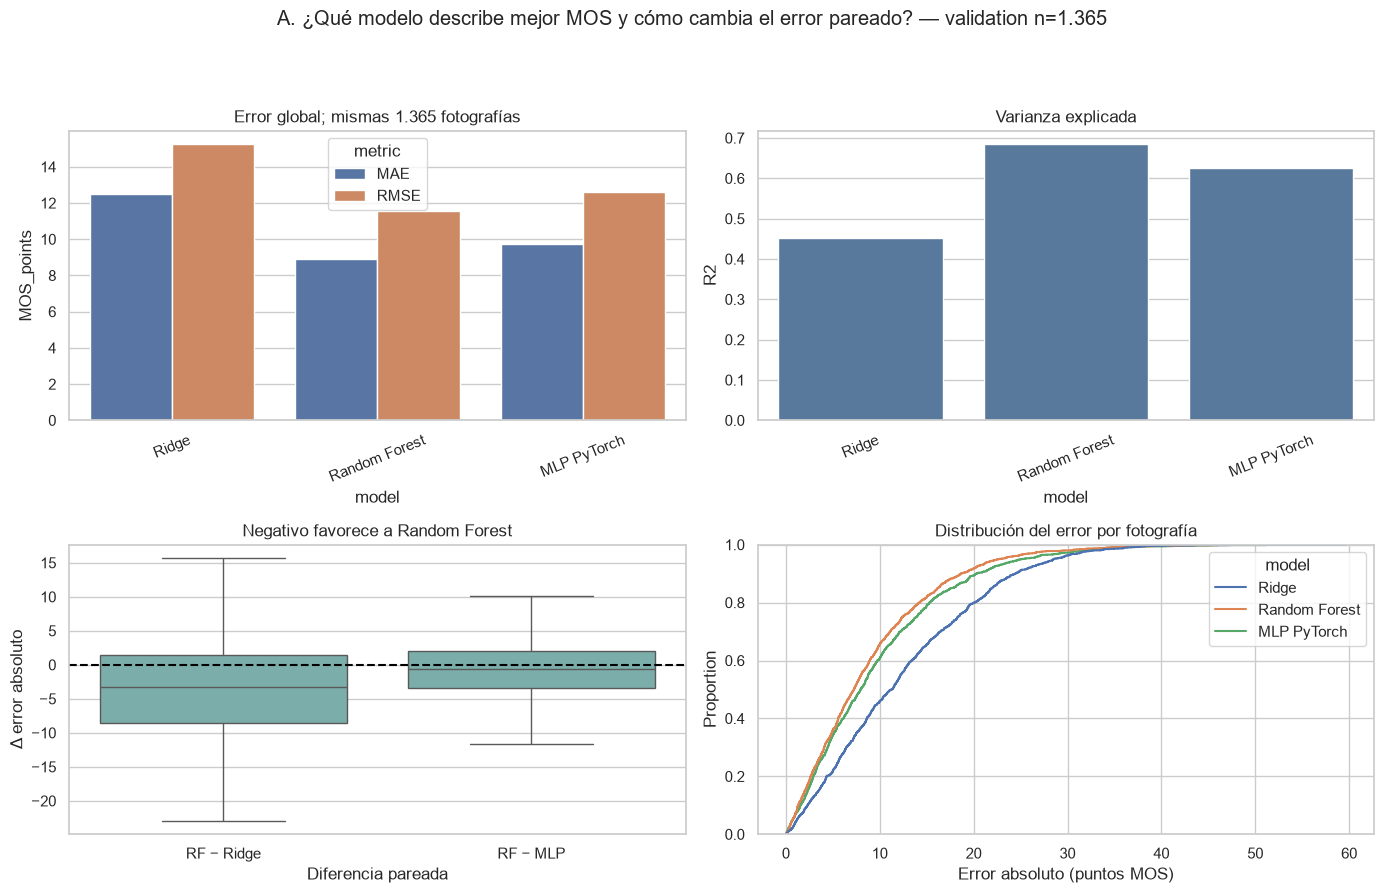

In [8]:
def bar(axis, data, x, y, title, rotation=0, **kwargs):
    sns.barplot(data=data, x=x, y=y, ax=axis, **kwargs).set_title(title); axis.tick_params(axis="x", rotation=rotation)
def scatter_pca(axis, data, hue, palette, title):
    sns.scatterplot(data=data, x="PCA1", y="PCA2", hue=hue, palette=palette, s=8, alpha=.35, linewidth=0, ax=axis)
    axis.set(xlabel=f"PC1 ({pca_two.explained_variance_ratio_[0]:.1%})",
        ylabel=f"PC2 ({pca_two.explained_variance_ratio_[1]:.1%})", title=title); axis.legend(fontsize=8)
figure, axes = plt.subplots(2, 2, figsize=(14, 9))
metrics_long = regression_summary.melt("model", value_vars=["MAE", "RMSE"], var_name="metric", value_name="MOS_points")
bar(axes[0, 0], metrics_long, "model", "MOS_points", "Error global; mismas 1.365 fotografías", 22, hue="metric")
bar(axes[0, 1], regression_summary, "model", "R2", "Varianza explicada", 22, color="#4C78A8")
sns.boxplot(data=paired_errors, x="comparison", y="absolute_error_difference", showfliers=False,
    color="#72B7B2", ax=axes[1, 0]); axes[1, 0].axhline(0, color="black", ls="--")
axes[1, 0].set(xlabel="Diferencia pareada", ylabel="Δ error absoluto", title="Negativo favorece a Random Forest")
sns.ecdfplot(data=regression_error_long, x="absolute_error", hue="model", ax=axes[1, 1])
axes[1, 1].set(xlabel="Error absoluto (puntos MOS)", title="Distribución del error por fotografía")
save(figure, "A_regresion_global_validation",
    "A. ¿Qué modelo describe mejor MOS y cómo cambia el error pareado? — validation n=1.365")

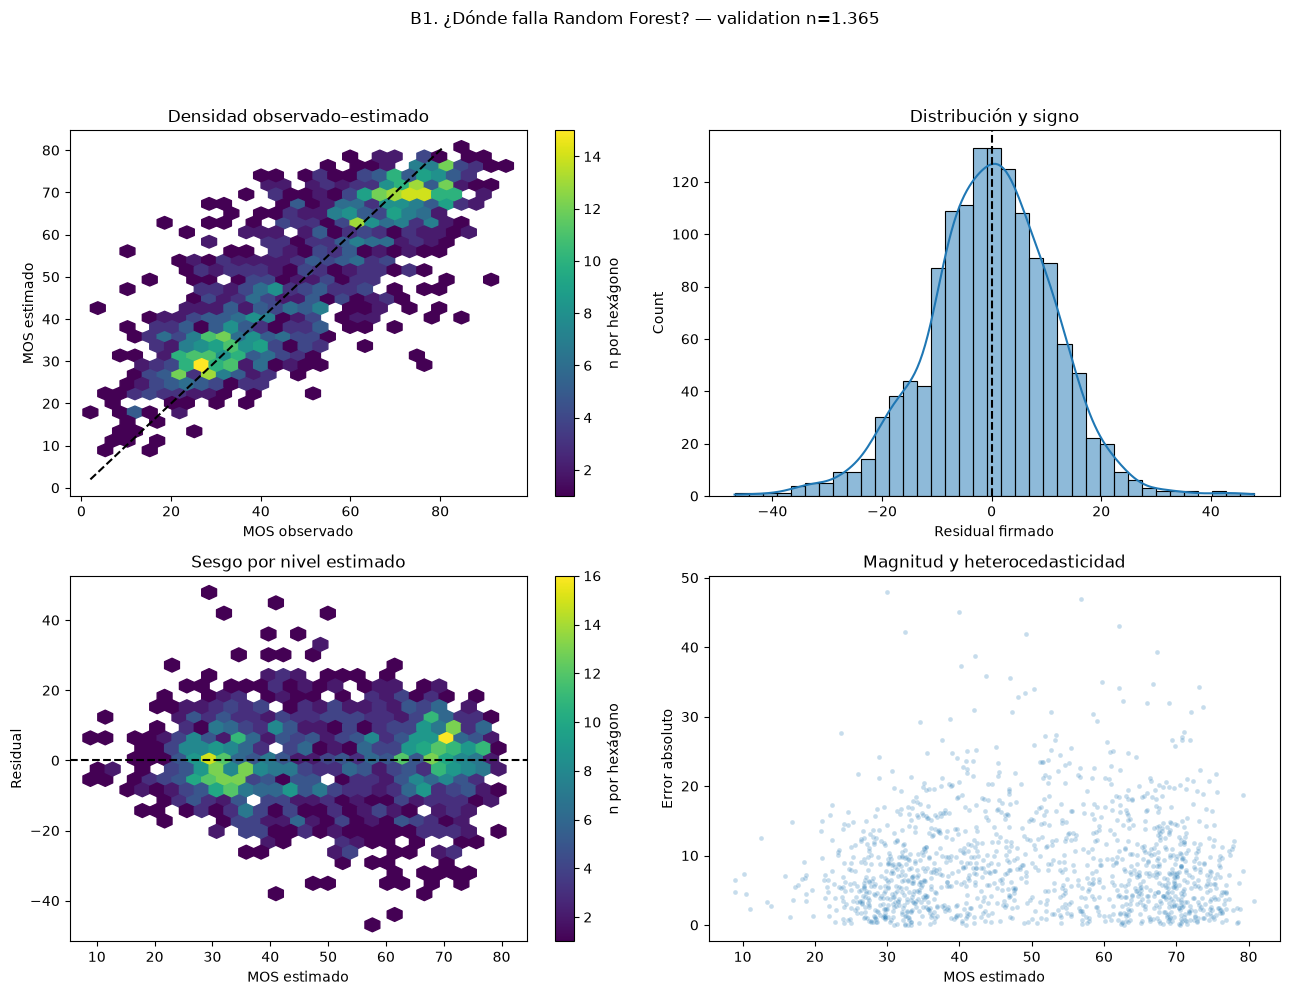

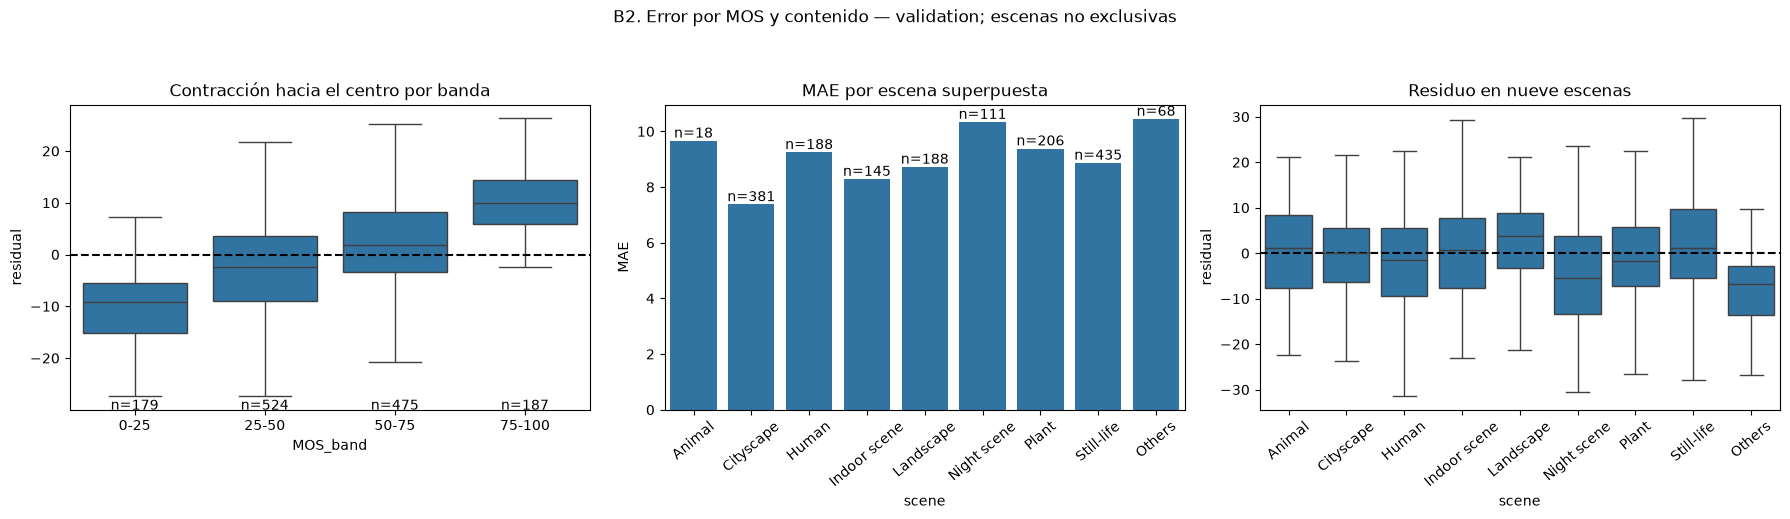

In [9]:
figure, axes = plt.subplots(2, 2, figsize=(13, 10))
hexbin = axes[0, 0].hexbin(regression_validation.MOS, regression_validation.MOS_predicted, gridsize=28, mincnt=1)
limits = regression_validation[["MOS", "MOS_predicted"]].agg(["min", "max"]).to_numpy().ravel()[[0, 3]]
axes[0, 0].plot(limits, limits, "k--"); axes[0, 0].set(xlabel="MOS observado", ylabel="MOS estimado",
    title="Densidad observado–estimado"); figure.colorbar(hexbin, ax=axes[0, 0], label="n por hexágono")
sns.histplot(regression_validation, x="residual", kde=True, ax=axes[0, 1]); axes[0, 1].axvline(0, color="black", ls="--")
axes[0, 1].set(xlabel="Residual firmado", title="Distribución y signo")
hexbin = axes[1, 0].hexbin(regression_validation.MOS_predicted, regression_validation.residual, gridsize=28, mincnt=1)
axes[1, 0].axhline(0, color="black", ls="--"); axes[1, 0].set(xlabel="MOS estimado", ylabel="Residual",
    title="Sesgo por nivel estimado"); figure.colorbar(hexbin, ax=axes[1, 0], label="n por hexágono")
sns.scatterplot(data=regression_validation, x="MOS_predicted", y="absolute_error", s=12, alpha=.25, ax=axes[1, 1])
axes[1, 1].set(xlabel="MOS estimado", ylabel="Error absoluto", title="Magnitud y heterocedasticidad")
save(figure, "B1_diagnostico_regresion_validation", "B1. ¿Dónde falla Random Forest? — validation n=1.365")
figure, axes = plt.subplots(1, 3, figsize=(18, 5.2))
sns.boxplot(data=regression_validation, x="MOS_band", y="residual", showfliers=False, ax=axes[0]); axes[0].axhline(0, c="k", ls="--")
axes[0].set(title="Contracción hacia el centro por banda"); bar(axes[1], scene_metrics, "scene", "MAE",
    "MAE por escena superpuesta", 40); sns.boxplot(data=scene_long, x="scene", y="residual", showfliers=False, ax=axes[2])
for index, row in band_metrics.reset_index().iterrows(): axes[0].text(index, axes[0].get_ylim()[0], f"n={int(row.n)}", ha="center")
for index, row in scene_metrics.iterrows(): axes[1].text(index, row.MAE, f"n={int(row.n)}", ha="center", va="bottom")
axes[2].axhline(0, c="k", ls="--"); axes[2].tick_params(axis="x", rotation=40); axes[2].set(title="Residuo en nueve escenas")
save(figure, "B2_error_condicionado_validation", "B2. Error por MOS y contenido — validation; escenas no exclusivas")

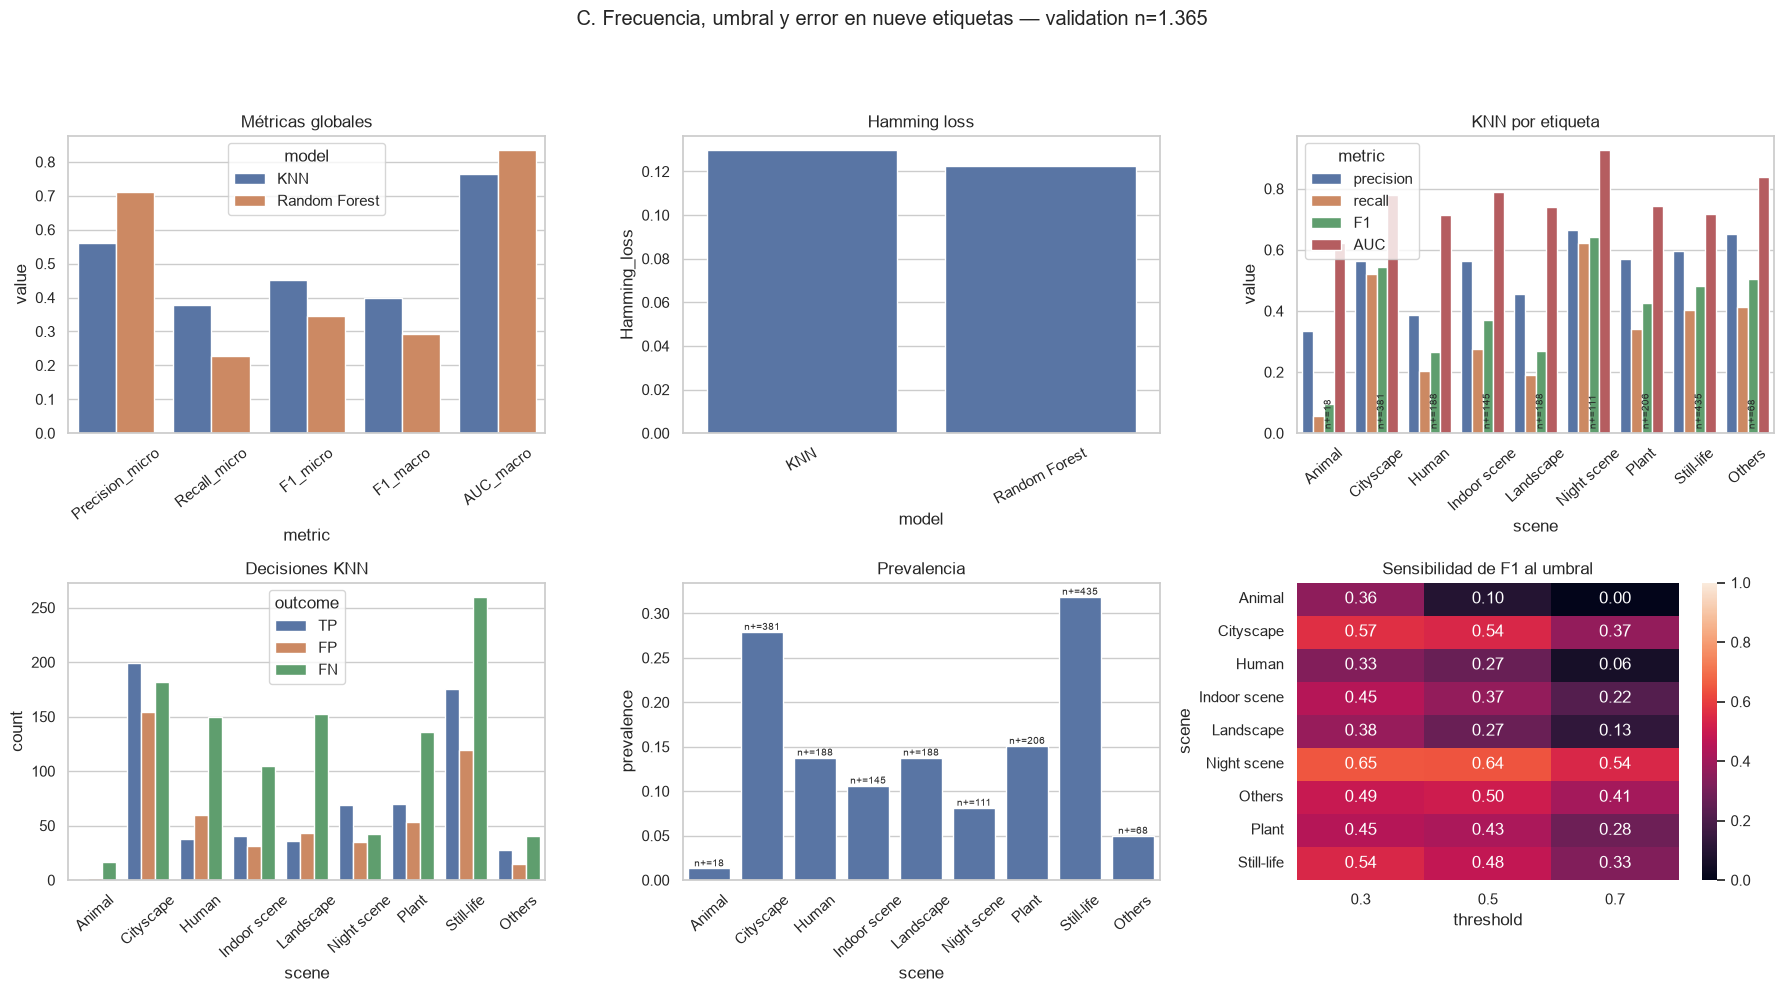

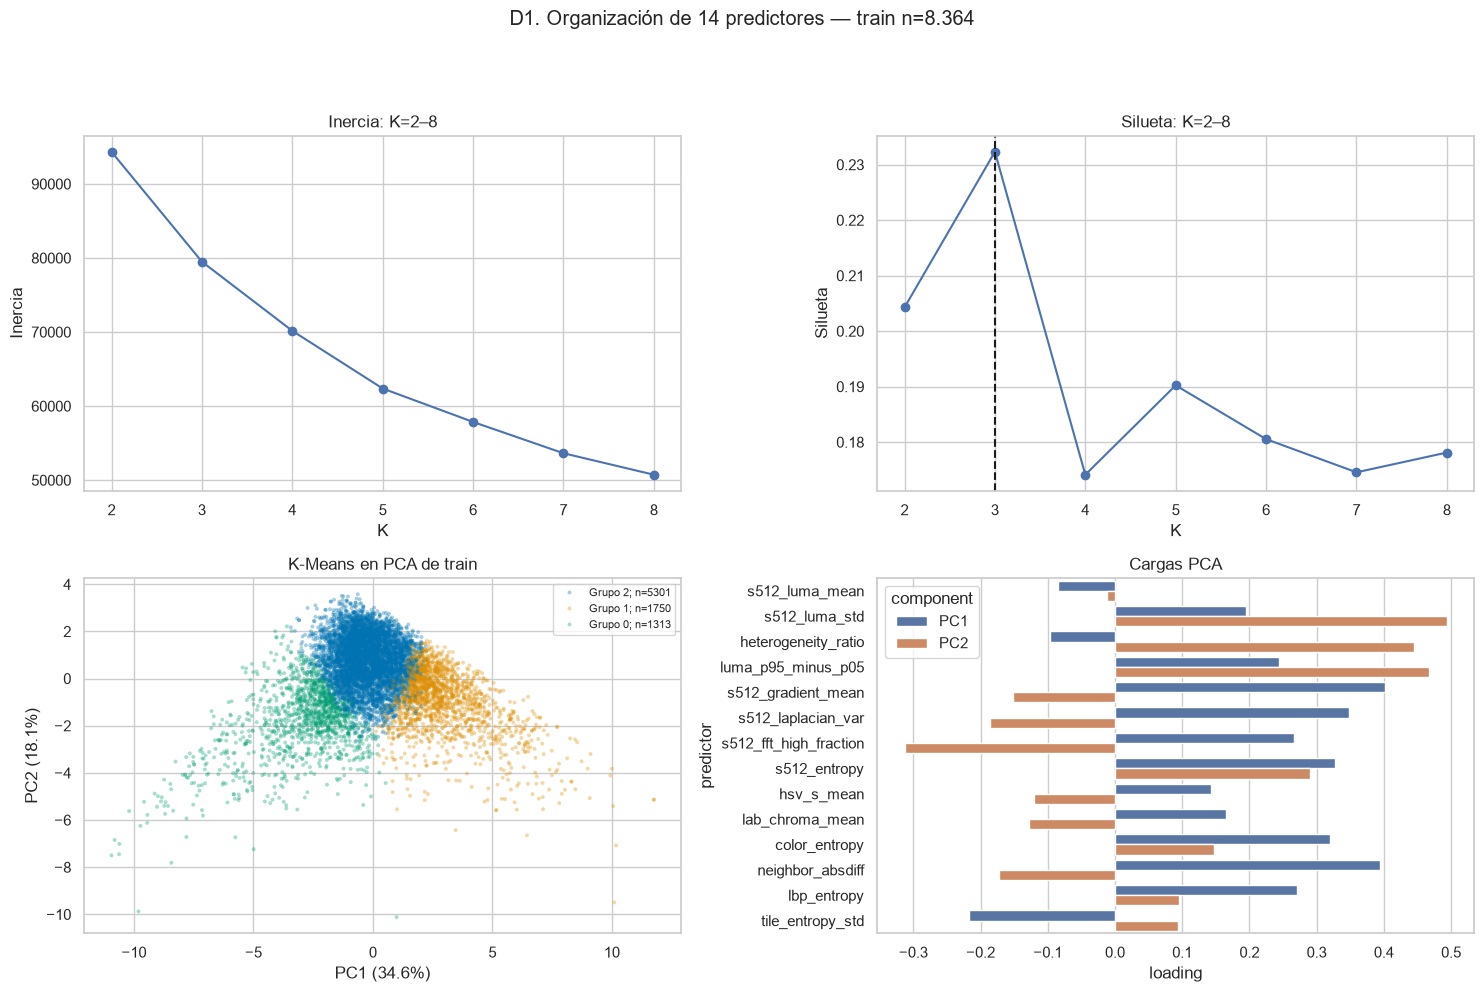

In [10]:
figure, axes = plt.subplots(2, 3, figsize=(18, 10))
global_long = classification_summary.melt("model", value_vars=["Precision_micro", "Recall_micro", "F1_micro",
    "F1_macro", "AUC_macro"], var_name="metric", value_name="value")
bar(axes[0, 0], global_long, "metric", "value", "Métricas globales", 38, hue="model")
bar(axes[0, 1], classification_summary, "model", "Hamming_loss", "Hamming loss", 28)
label_long = label_metrics.melt(["scene", "support_positive", "prevalence"], value_vars=["precision", "recall", "F1", "AUC"],
    var_name="metric", value_name="value"); bar(axes[0, 2], label_long, "scene", "value", "KNN por etiqueta", 42, hue="metric")
for index, row in label_metrics.iterrows(): axes[0, 2].text(index, .02, f"n+={row.support_positive}", rotation=90, fontsize=7)
confusion = label_metrics.melt("scene", value_vars=["TP", "FP", "FN"], var_name="outcome", value_name="count")
bar(axes[1, 0], confusion, "scene", "count", "Decisiones KNN", 42, hue="outcome")
bar(axes[1, 1], label_metrics, "scene", "prevalence", "Prevalencia", 42)
for index, row in label_metrics.iterrows(): axes[1, 1].text(index, row.prevalence, f"n+={row.support_positive}", ha="center", va="bottom", fontsize=7)
sns.heatmap(threshold_metrics.pivot(index="scene", columns="threshold", values="F1"), vmin=0, vmax=1,
    annot=True, fmt=".2f", ax=axes[1, 2]); axes[1, 2].set(title="Sensibilidad de F1 al umbral")
save(figure, "C_clasificacion_multietiqueta_validation",
    "C. Frecuencia, umbral y error en nueve etiquetas — validation n=1.365")
figure, axes = plt.subplots(2, 2, figsize=(15, 10)); pca_plot = pd.DataFrame(pca_coordinates, columns=["PCA1", "PCA2"])
for axis, column, ylabel in ((axes[0, 0], "inertia", "Inercia"), (axes[0, 1], "silhouette", "Silueta")):
    axis.plot(k_selection.K, k_selection[column], marker="o"); axis.set(xlabel="K", ylabel=ylabel, title=f"{ylabel}: K=2–8")
axes[0, 1].axvline(selected_k, c="k", ls="--")
pca_plot["K-Means"] = pd.Series(kmeans_labels).map({x: f"Grupo {x}; n={(kmeans_labels == x).sum()}" for x in range(3)})
scatter_pca(axes[1, 0], pca_plot, "K-Means", "colorblind", "K-Means en PCA de train")
loadings = pca_loadings[["PC1", "PC2"]].reset_index(names="predictor").melt("predictor", var_name="component", value_name="loading")
sns.barplot(data=loadings, x="loading", y="predictor", hue="component", ax=axes[1, 1]); axes[1, 1].set(title="Cargas PCA")
save(figure, "D1_kmeans_pca_train", "D1. Organización de 14 predictores — train n=8.364")

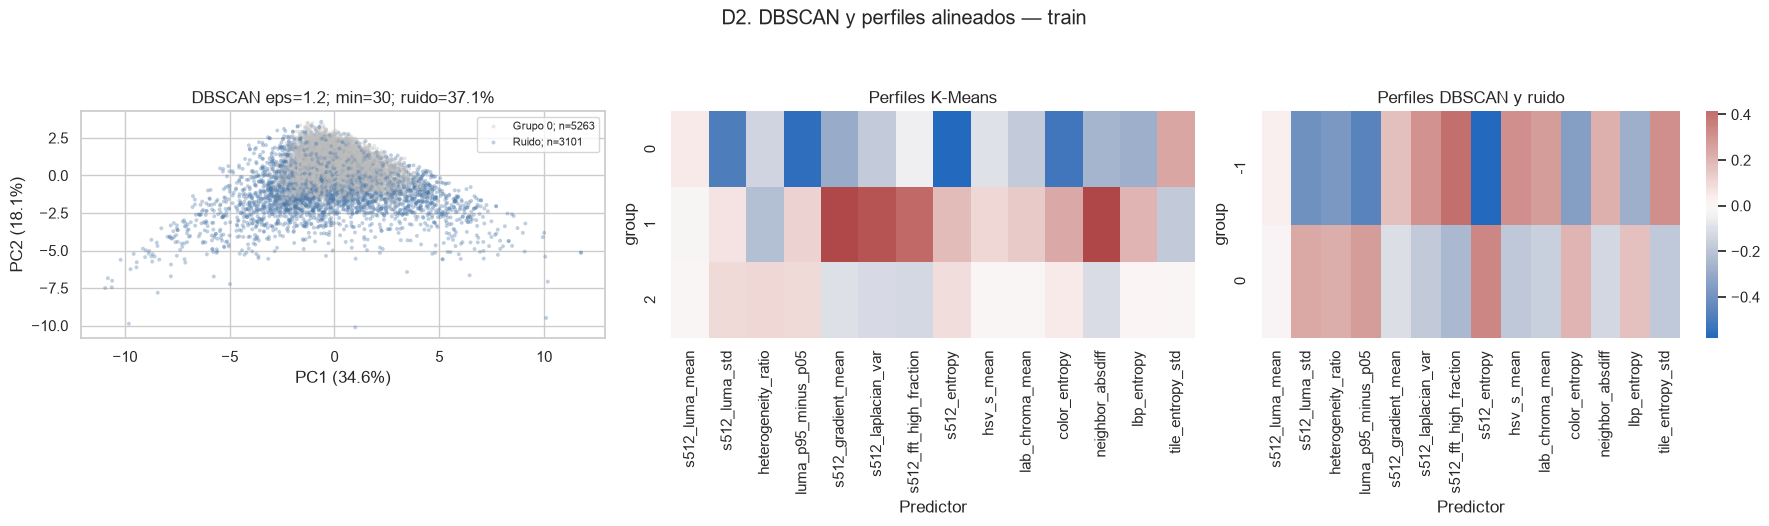

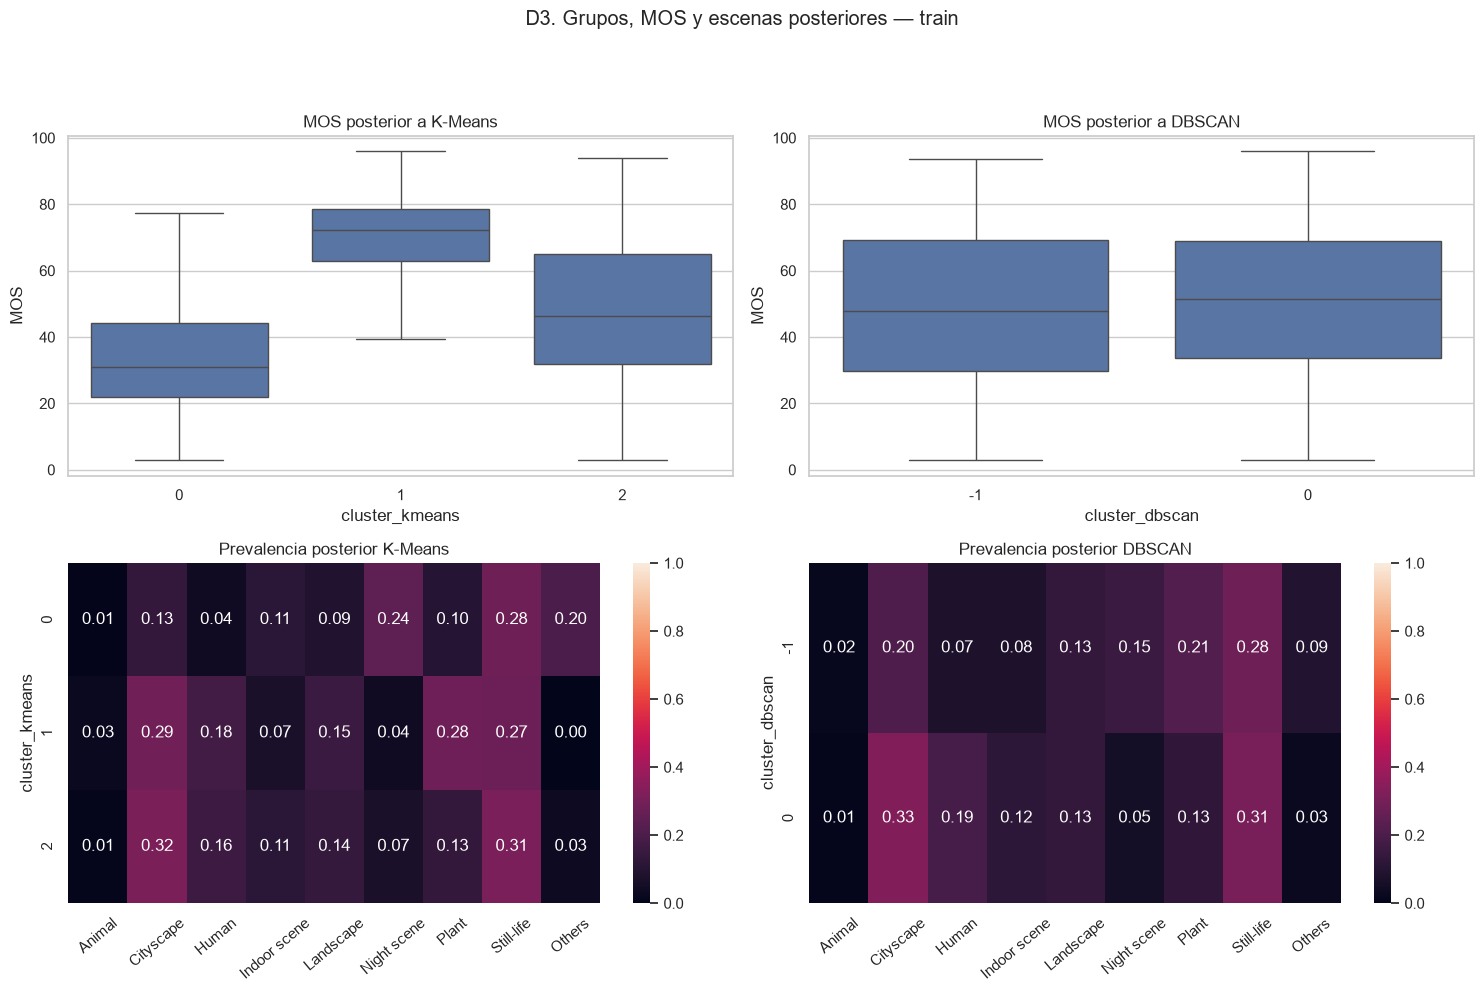

In [11]:
figure, axes = plt.subplots(1, 3, figsize=(18, 5.3)); values = sorted(set(dbscan_labels))
pca_plot["DBSCAN"] = pd.Series(dbscan_labels).map({x: f"{'Ruido' if x == -1 else f'Grupo {x}'}; n={(dbscan_labels == x).sum()}" for x in values})
scatter_pca(axes[0], pca_plot, "DBSCAN", ["#BDBDBD", "#4C78A8"],
    f"DBSCAN eps={choice.eps:g}; min={int(choice.min_samples)}; ruido={choice.noise_fraction:.1%}")
z_columns = [f"z_{x}" for x in PREDICTORS]
for axis, frame, title in ((axes[1], kmeans_profiles, "Perfiles K-Means"), (axes[2], dbscan_profiles, "Perfiles DBSCAN y ruido")):
    sns.heatmap(frame[z_columns].set_axis(PREDICTORS, axis=1), center=0, cmap="vlag", ax=axis, cbar=axis is axes[2])
    axis.set(xlabel="Predictor", title=title)
save(figure, "D2_dbscan_perfiles_train", "D2. DBSCAN y perfiles alineados — train")
figure, axes = plt.subplots(2, 2, figsize=(15, 10)); prevalence = [f"prevalence_{x}" for x in SCENES]
for axis, column, title in ((axes[0, 0], "cluster_kmeans", "MOS posterior a K-Means"),
    (axes[0, 1], "cluster_dbscan", "MOS posterior a DBSCAN")):
    sns.boxplot(data=clusters_train, x=column, y="MOS", showfliers=False, ax=axis); axis.set_title(title)
for axis, frame, title in ((axes[1, 0], kmeans_posthoc, "Prevalencia posterior K-Means"),
    (axes[1, 1], dbscan_posthoc, "Prevalencia posterior DBSCAN")):
    sns.heatmap(frame[prevalence].set_axis(SCENES, axis=1), vmin=0, vmax=1, annot=True, fmt=".2f", ax=axis)
    axis.set_title(title); axis.tick_params(axis="x", rotation=40)
save(figure, "D3_posthoc_clusters_train", "D3. Grupos, MOS y escenas posteriores — train")

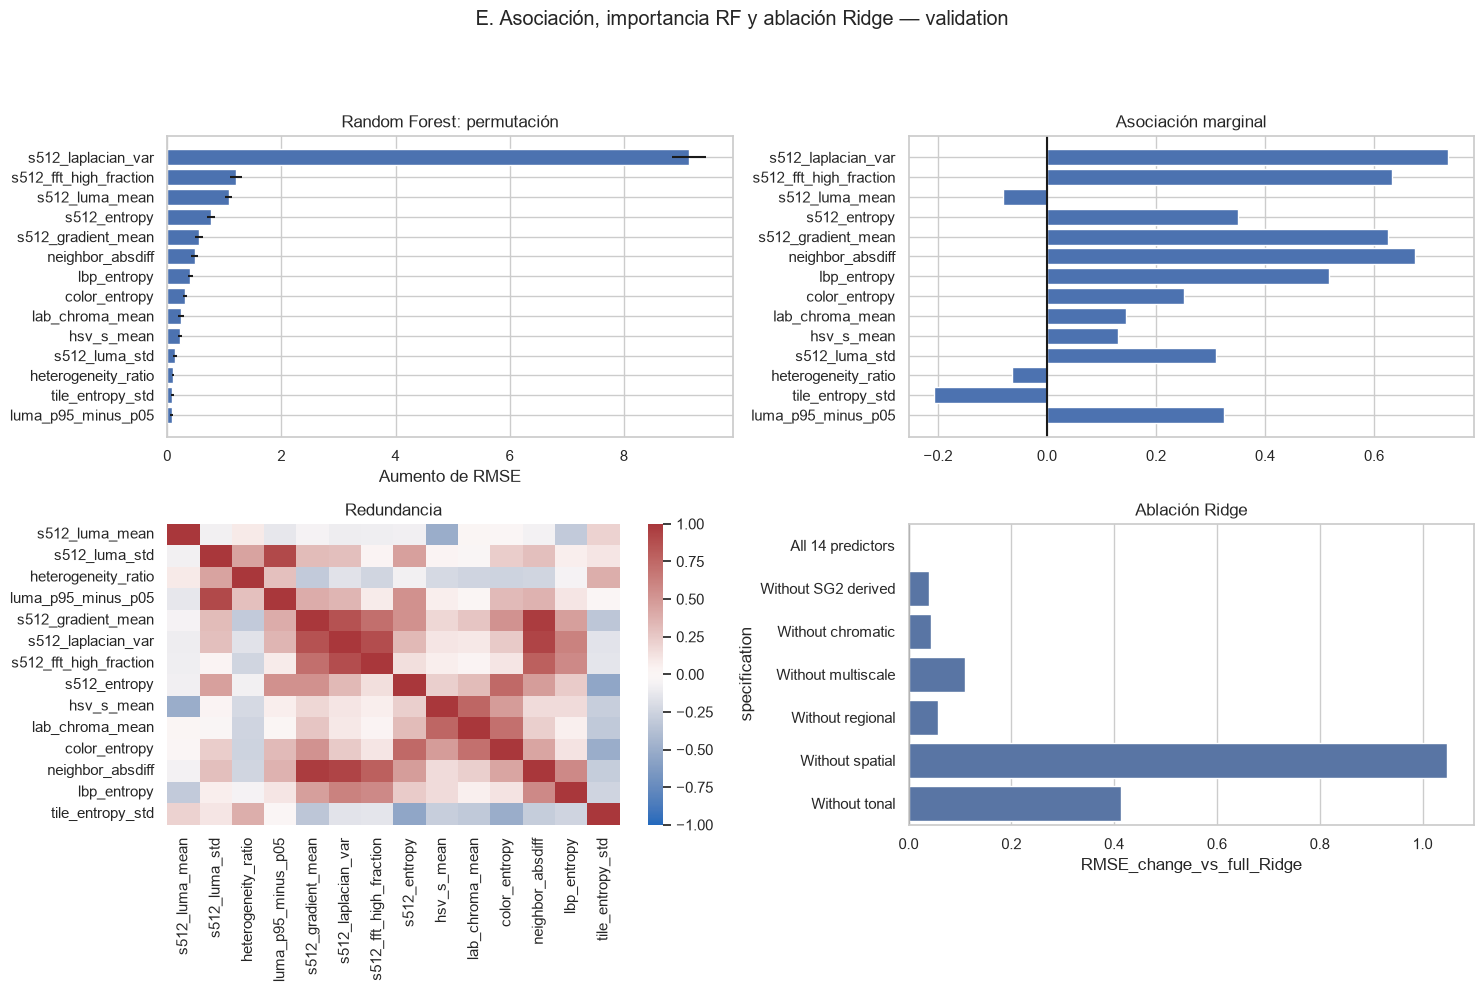

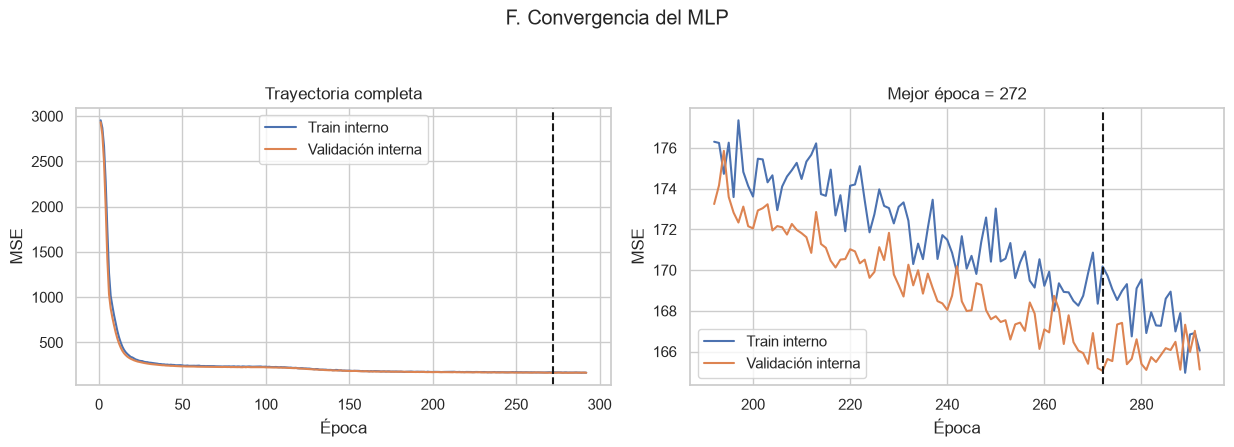

In [12]:
figure, axes = plt.subplots(2, 2, figsize=(15, 10)); axes = axes.ravel(); ordered = importance.sort_values("permutation_RMSE_mean")
axes[0].barh(ordered.predictor, ordered.permutation_RMSE_mean, xerr=ordered.permutation_RMSE_sd)
axes[0].set(title="Random Forest: permutación", xlabel="Aumento de RMSE")
axes[1].barh(ordered.predictor, ordered.spearman_rho); axes[1].axvline(0, c="k"); axes[1].set(title="Asociación marginal")
sns.heatmap(correlation_matrix, vmin=-1, vmax=1, center=0, cmap="vlag", ax=axes[2]); axes[2].set_title("Redundancia")
bar(axes[3], ablation, "RMSE_change_vs_full_Ridge", "specification", "Ablación Ridge"); axes[3].axvline(0, c="k")
save(figure, "E_interpretabilidad_validation", "E. Asociación, importancia RF y ablación Ridge — validation")
figure, axes = plt.subplots(1, 2, figsize=(12.5, 4.5)); zoom = history.query("epoch >= @best_epoch - 80")
for axis, frame, title in ((axes[0], history, "Trayectoria completa"), (axes[1], zoom, f"Mejor época = {best_epoch}")):
    axis.plot(frame.epoch, frame.train_mse, label="Train interno"); axis.plot(frame.epoch, frame.stop_mse, label="Validación interna")
    axis.axvline(best_epoch, c="k", ls="--"); axis.set(xlabel="Época", ylabel="MSE", title=title); axis.legend()
save(figure, "F_mlp_perdida_train", "F. Convergencia del MLP")

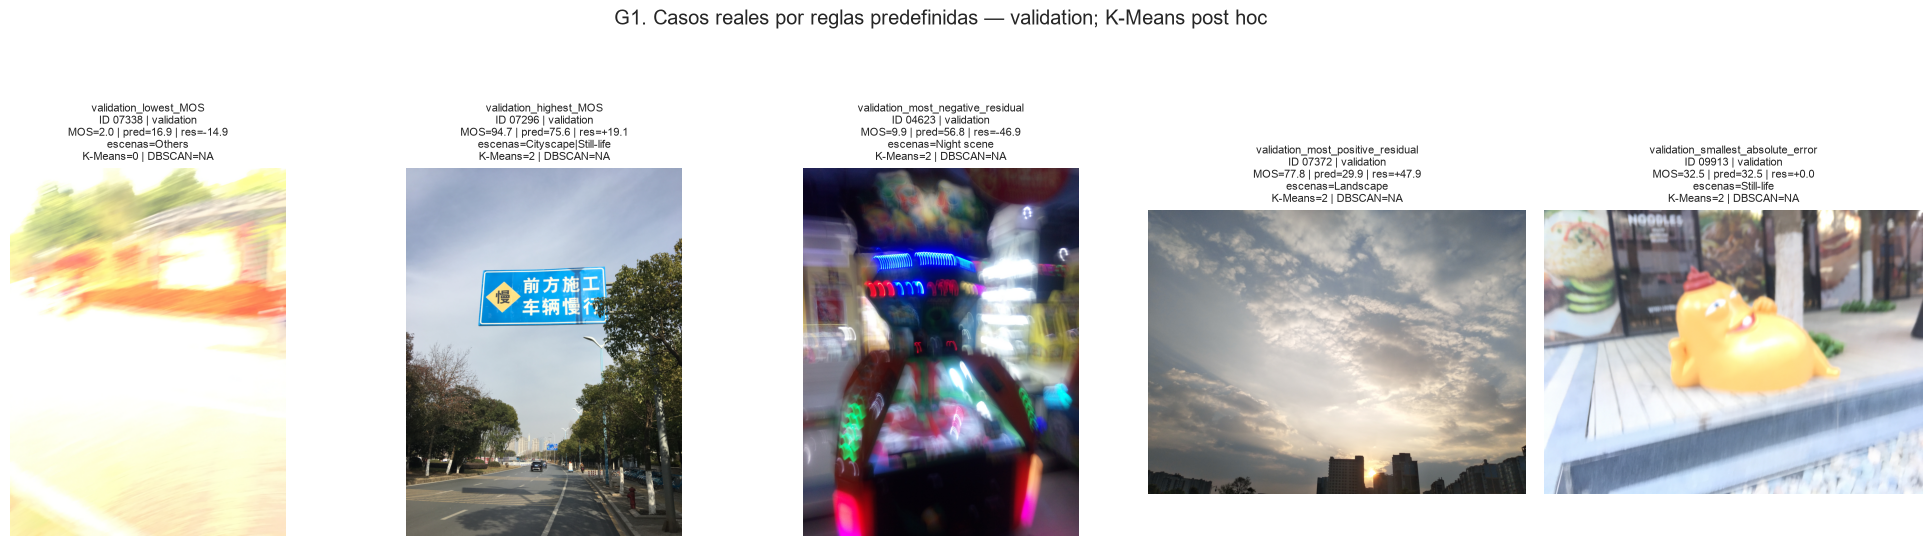

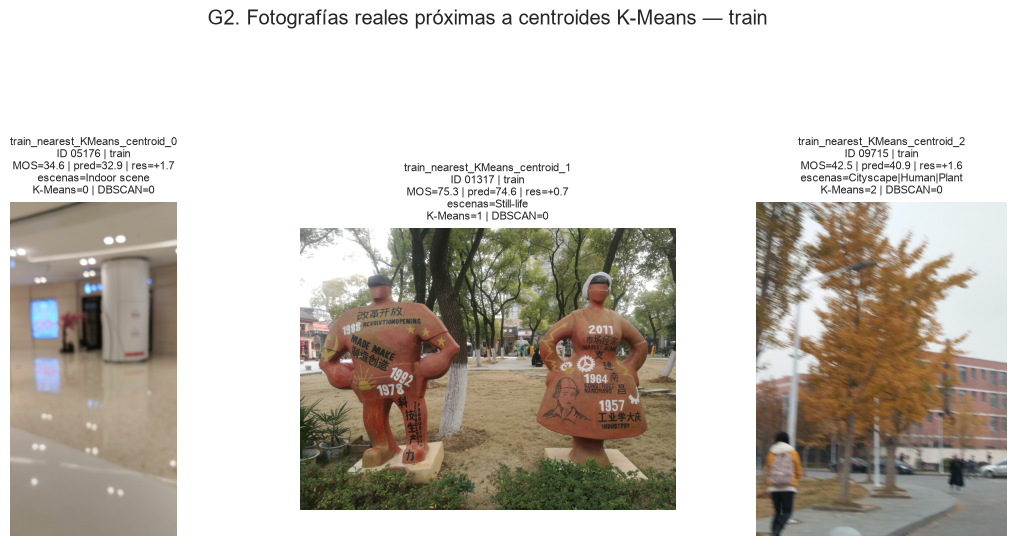

In [13]:
def gallery_plot(cases, name, title):
    figure, axes = plt.subplots(1, len(cases), figsize=(4 * len(cases), 5.5))
    for axis, (_, row) in zip(np.atleast_1d(axes), cases.iterrows()):
        with Image.open(IMAGES / f"{row.image_id}.jpg") as raw: axis.imshow(ImageOps.exif_transpose(raw).convert("RGB"))
        db = "NA" if pd.isna(row.cluster_dbscan) else int(row.cluster_dbscan)
        axis.set_title(f"{row.selection_rule}\nID {row.image_id} | {row.split}\nMOS={row.MOS:.1f} | pred={row.MOS_predicted:.1f} | "
            f"res={row.residual:+.1f}\nescenas={row.active_scenes}\nK-Means={int(row.cluster_kmeans_posthoc)} | DBSCAN={db}", fontsize=8)
        axis.axis("off")
    save(figure, name, title, .86)
gallery_plot(gallery.query("split == 'validation'"), "G1_casos_reales_validation",
    "G1. Casos reales por reglas predefinidas — validation; K-Means post hoc")
gallery_plot(gallery.query("split == 'train'"), "G2_prototipos_reales_train",
    "G2. Fotografías reales próximas a centroides K-Means — train")

## Test histórico, exportación y controles

In [14]:
test_ids = set(test_sealed.image_id)
test = annotations(FILES["scores"], test_ids).merge(annotations(FILES["scenes"], test_ids),
    on=["image_id", "Image name"], validate="one_to_one").merge(test_sealed, on="image_id")
test[TARGETS] = (test[SCENES] > 0).astype("int8").set_axis(TARGETS, axis=1)
X_test, y_test, Y_test = test[PREDICTORS], test.MOS, test[TARGETS].to_numpy()
development_full = pd.concat([train, validation]); X_development = development_full[PREDICTORS]
final_regressor = base.clone(regression_models["Random Forest"]).fit(X_development, development_full.MOS)
final_classifier = base.clone(classification_models["KNN"]).fit(X_development, development_full[TARGETS].to_numpy())
test_regression_prediction = final_regressor.predict(X_test); test_classification_prediction = final_classifier.predict(X_test)
test_classification_scores = scores(final_classifier, X_test)
regression_test = reg_table(test, test_regression_prediction); classification_test = class_table(test, Y_test,
    test_classification_prediction, test_classification_scores)
for frame in (regression_test, classification_test): frame["status"] = "historical_reproducibility_frozen_decisions"
summary_models = pd.concat([regression_summary.assign(task="regression", split="validation"),
    classification_summary.assign(task="multilabel_classification", split="validation")], ignore_index=True)
gallery_columns = ["image_id", "sha256", "split", "selection_rule", "relative_jpeg_path", "MOS", "MOS_predicted",
    "residual", "absolute_error", "active_scenes", "cluster_kmeans_posthoc", "cluster_dbscan", "cluster_assignment_source"]
tables = {"predicciones_regresion_validacion.csv": regression_validation,
    "predicciones_finalistas_validacion.csv": regression_finalists,
    "diferencias_error_pareadas_validacion.csv": paired_errors,
    "predicciones_regresion_test_reproducibilidad.csv": regression_test,
    "clasificacion_validacion.csv": classification_validation, "clasificacion_test_reproducibilidad.csv": classification_test,
    "clusters_entrenamiento.csv": clusters_train, "resumen_modelos.csv": summary_models,
    "importancia_permutacion.csv": importance, "metricas_por_escena.csv": scene_metrics,
    "metricas_clasificacion_por_escena.csv": label_metrics, "ablacion_familias_ridge.csv": ablation,
    "sensibilidad_umbral_clasificacion.csv": threshold_metrics, "seleccion_kmeans.csv": k_selection.drop(columns="model"),
    "seleccion_dbscan.csv": dbscan_selection, "perfil_posthoc_kmeans.csv": kmeans_posthoc.reset_index(),
    "perfil_posthoc_dbscan.csv": dbscan_posthoc.reset_index(), "varianza_pca.csv": pd.DataFrame({"component": ["PC1", "PC2"],
        "explained_variance_ratio": pca_two.explained_variance_ratio_}), "indice_galeria_casos.csv": gallery[gallery_columns],
    "historial_mlp.csv": history}
for filename, frame in tables.items(): frame.to_csv(RESULTS / filename, index=False)
kmeans_profiles.to_csv(RESULTS / "perfiles_clusters.csv", index_label="cluster_kmeans")
dbscan_profiles.to_csv(RESULTS / "perfiles_dbscan.csv", index_label="cluster_dbscan")
band_metrics.to_csv(RESULTS / "metricas_por_banda_mos.csv"); pca_loadings.to_csv(RESULTS / "cargas_pca.csv")
manifest = pd.DataFrame({"order": range(68), "descriptor": DESCRIPTORS}); manifest["is_predictor"] = manifest.descriptor.isin(PREDICTORS)
manifest["family"] = manifest.descriptor.map(FAMILIES); manifest.to_csv(RESULTS / "manifiesto_descriptores.csv", index=False)
metadata[["image_id", "sha256", "split", *DESCRIPTORS, "heterogeneity_ratio", "luma_p95_minus_p05"]].to_csv(
    RESULTS / "descriptores_por_imagen.csv", index=False)
models = {"modelo_regresion_final.joblib": final_regressor, "modelo_clasificacion_final.joblib": final_classifier,
    "transformador_clustering.joblib": cluster_preprocessor, "kmeans.joblib": kmeans, "dbscan.joblib": dbscan,
    "pca_visualizacion.joblib": pca_two, "transformador_mlp.joblib": mlp_preprocessor,
    "dbscan_parametros.joblib": {"eps": float(choice.eps), "min_samples": int(choice.min_samples)}}
for filename, model in models.items(): joblib.dump(model, MODELS / filename)
torch.save({"state_dict": best_state, "predictors": PREDICTORS, "best_epoch": best_epoch}, MODELS / "mlp_train.pt")
test_regression_metrics = reg_metrics(y_test, test_regression_prediction)
test_classification_metrics = class_metrics(Y_test, test_classification_prediction, test_classification_scores)
event = {"timestamp": datetime.now(ZoneInfo("America/Bogota")).isoformat(),
    "status": "historical_reproducibility_frozen_decisions", "frozen_decisions": frozen,
    "regression_test": test_regression_metrics, "classification_test": test_classification_metrics}
(RESULTS / "evento_test_reproducibilidad.json").write_text(json.dumps(event, indent=2), encoding="utf-8")

1031

In [15]:
expected_figures = """A_regresion_global_validation B1_diagnostico_regresion_validation B2_error_condicionado_validation
C_clasificacion_multietiqueta_validation D1_kmeans_pca_train D2_dbscan_perfiles_train D3_posthoc_clusters_train
E_interpretabilidad_validation F_mlp_perdida_train G1_casos_reales_validation G2_prototipos_reales_train""".split()
assert np.allclose(regression_summary.set_index("model").loc["Random Forest", ["MAE", "RMSE", "R2"]],
    [8.926698087423688, 11.57665869103917, .6839482656563363])
assert np.isclose(classification_summary.set_index("model").loc["KNN", "F1_micro"], .4511691884456671)
assert kmeans_profiles.n.astype(int).tolist() == [1313, 1750, 5301]
assert dict(zip(*final_counts)) == {-1: 3101, 0: 5263} and np.array_equal(dbscan.labels_, dbscan_labels)
assert all(count >= dbscan.min_samples for label, count in zip(*final_counts) if label != -1)
assert {x.stem for x in FIGURES.glob("*.png")} == set(expected_figures)
assert {x.stem for x in FIGURES.glob("*.svg")} == set(expected_figures)
closure = {"status": "PASS", "code_cells": 15, "rows": len(metadata), "unique_sha": metadata.sha256.nunique(),
    "split_counts": split_counts.to_dict(), "extraction_minutes": extraction_minutes, "figures_png": 11, "figures_svg": 11,
    "dbscan_parameters": dbscan.get_params(), "dbscan_counts": {str(k): int(v) for k, v in zip(*final_counts)},
    "notebook_inputs": [str(x) for x in FILES.values()] + [str(IMAGES / "*.jpg")],
    "test_status": "historical_reproducibility_frozen_decisions"}
(RESULTS / "control_cierre.json").write_text(json.dumps(closure, indent=2), encoding="utf-8")
display(pd.Series(test_regression_metrics), pd.Series(test_classification_metrics)); print(json.dumps(closure, indent=2))

MAE      9.050575
RMSE    11.568386
R2       0.696021
dtype: float64

F1_micro           0.425561
F1_macro           0.369052
Precision_micro    0.536118
Recall_micro       0.352806
Hamming_loss       0.132362
Subset_accuracy    0.281519
AUC_macro          0.755733
dtype: float64

{
  "status": "PASS",
  "code_cells": 15,
  "rows": 11125,
  "unique_sha": 10803,
  "split_counts": {
    "train": 8364,
    "test": 1396,
    "validation": 1365
  },
  "extraction_minutes": 11.011356663703918,
  "figures_png": 11,
  "figures_svg": 11,
  "dbscan_parameters": {
    "algorithm": "auto",
    "eps": 1.2,
    "leaf_size": 30,
    "metric": "euclidean",
    "metric_params": null,
    "min_samples": 30,
    "n_jobs": -1,
    "p": null
  },
  "dbscan_counts": {
    "-1": 3101,
    "0": 5263
  },
  "notebook_inputs": [
    "RUTA_DEL_PROYECTO\\spaq\\SPAQ\\Annotations\\MOS and Image attribute scores.xlsx",
    "RUTA_DEL_PROYECTO\\spaq\\SPAQ\\Annotations\\Scene category labels.xlsx",
    "RUTA_DEL_PROYECTO\\spaq\\SPAQ\\Annotations\\EXIF_tags.xlsx",
    "RUTA_DEL_PROYECTO\\spaq\\SPAQ\\TestImage\\*.jpg"
  ],
  "test_status": "historical_reproducibility_frozen_decisions"
}
